In [ ]:
import numpy as np
import xtrack as xt
import matplotlib.pyplot as plt

# env = xt.load('lhc_run3_b1.json')
# line = env.b1
line = xt.load('levelling.26_b1.json.gz')
line_b2 = xt.load('levelling.26_b4.json.gz')

tt = line.get_table(attr=True)
tw = line.twiss()

tw_b2 = line_b2.twiss()

Brho = 6.8e12/3e8

Loading line from dict:  18%|█▊        | 36514/204179 [00:01<00:05, 29377.67it/s]/Users/frederik/pythondev/xtrack/xtrack/beam_elements/elements.py:793: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
Loading line from dict: 100%|██████████| 204179/204179 [00:06<00:00, 31602.61it/s]


Done loading line from dict.           


Loading line from dict: 100%|██████████| 204179/204179 [00:05<00:00, 34528.82it/s]


Done loading line from dict.           


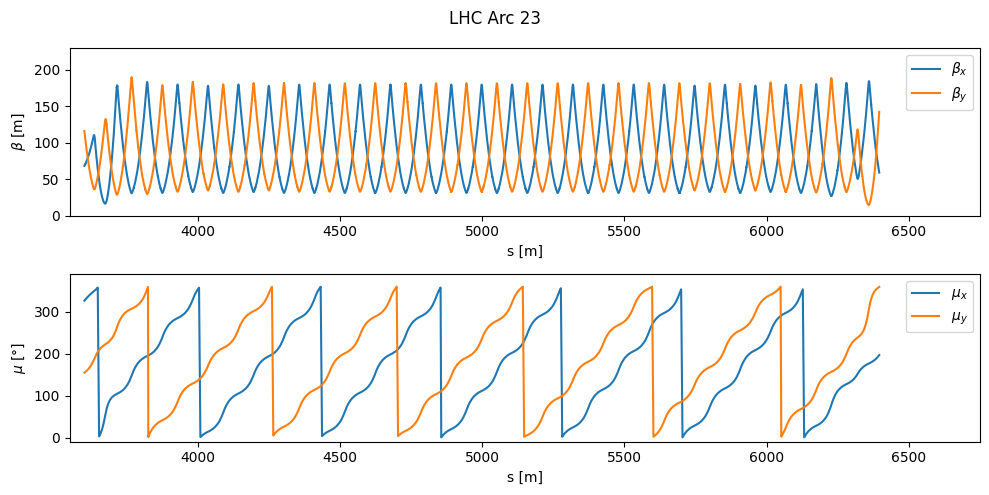

In [2]:
start = 's.ds.r2.b1'
end   = 'e.ds.l3.b1'
fig, ax = plt.subplots(2, 1, figsize=(10, 5))
ax[0].plot(tw.rows[start:end].s, tw.rows[start:end].betx, label=r'$\beta_x$')
ax[0].plot(tw.rows[start:end].s, tw.rows[start:end].bety, label=r'$\beta_y$')
ax[1].plot(tw.rows[start:end].s, tw.rows[start:end].mux % 1 * 360, label=r'$\mu_x$')
ax[1].plot(tw.rows[start:end].s, tw.rows[start:end].muy % 1 * 360, label=r'$\mu_y$')
ax[0].set_xlabel('s [m]')
ax[1].set_xlabel('s [m]')
ax[0].set_ylabel(r'$\beta$ [m]')
ax[1].set_ylabel(r'$\mu$ [°]')
ax[0].set_xlim(3550, 6750)
ax[0].set_ylim(0, 230)
ax[1].set_xlim(3550, 6750)
ax[1].set_ylim(-10, 390)
# ax[01].set_yscale('log')
ax[0].legend(loc='upper right')
ax[1].legend(loc='upper right')
fig.suptitle('LHC Arc 23')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/lhc_arc23.png', dpi=300)

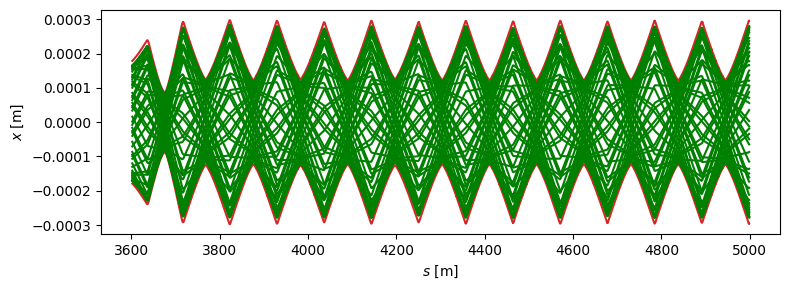

In [55]:
start = 's.ds.r2.b1'
end   = 'e.ds.l3.b1'
s_start = tt.rows[start].s[0]
s_end   = s_start + (tt.rows[end].s[0] - s_start)/2

x = None
part = line.build_particles(x_norm=[0.9], px_norm=[0.3],nemitt_x=3.5e-6, nemitt_y=3.5e-6)
for _ in range(50):
    line.track(part, num_turns=1, turn_by_turn_monitor='ONE_TURN_EBE')
    if x is None:
        x = line.record_last_track.x[0]
        s = line.record_last_track.s[0]
        mask = (s >= s_start) & (s <= s_end)
        x = np.array([x[mask]])
        s = np.array([s[mask]])
    else:
        x = np.append(x, [line.record_last_track.x[0][mask]], axis=0)
        s = np.append(s, [line.record_last_track.s[0][mask]], axis=0)

fig, ax = plt.subplots(1, 1, figsize=(8, 3))
ax.plot(tw.rows[s_start:s_end:'s'].s, np.sqrt(3.5e-6/tw.gamma0 * tw.rows[s_start:s_end:'s'].betx), c='tab:red')
ax.plot(tw.rows[s_start:s_end:'s'].s, -np.sqrt(3.5e-6/tw.gamma0 * tw.rows[s_start:s_end:'s'].betx), c='tab:red')
ax.plot(s.T, x.T, 'g-')
ax.set_xlabel('$s$ [m]')
ax.set_ylabel(r'$x$ [m]')
# fig.suptitle('Fifty turns particle tracking')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/lhc_50turn.png', dpi=300)

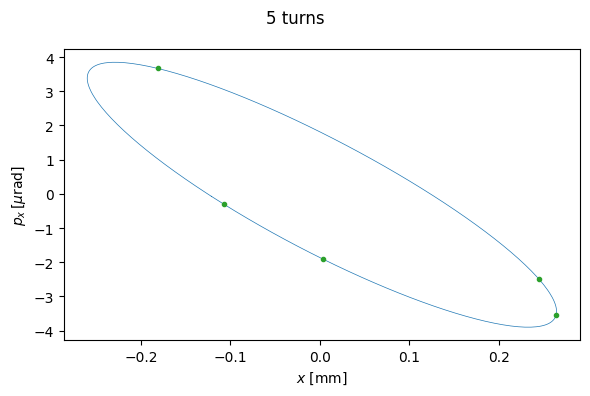

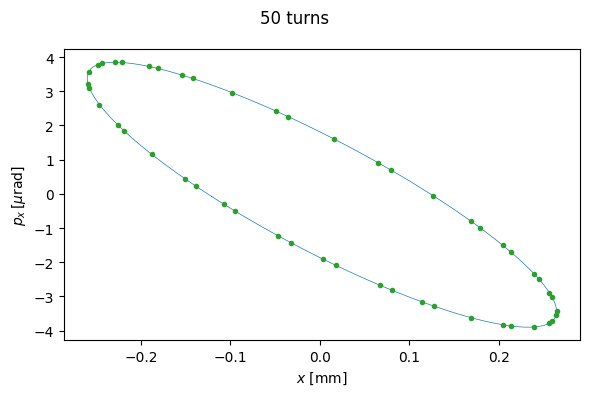

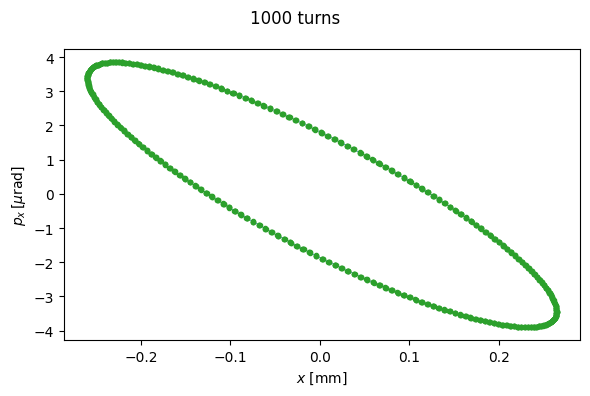

In [45]:
# num_turns = 1000
# mon = xt.ParticlesMonitor(start_at_turn=0, stop_at_turn=num_turns, num_particles=1)
# line.insert('monitor', mon, 'tcp.c6l7.b1_mken')
# part = line.build_particles(x_norm=[1], px_norm=[0], nemitt_x=3.5e-6, nemitt_y=3.5e-6)
# line.track(part, num_turns=num_turns)

theta = np.arctan2(mon.px[0], mon.x[0])
idx = np.argsort(theta)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot((1e3*mon.x[0][idx]).tolist() + [1e3*mon.x[0][idx[0]]],
        (1e6*mon.px[0][idx]).tolist() + [1e6*mon.px[0][idx[0]]], 'tab:blue', lw=0.5)
ax.plot(1e3*mon.x.T[:5], 1e6*mon.px.T[:5], '.', c='tab:green')
ax.set_xlabel('$x$ [mm]')
ax.set_ylabel(r'$p_x\,[\mu\text{rad}]$')
fig.suptitle('5 turns')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/phase_space_5.png', dpi=300)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot((1e3*mon.x[0][idx]).tolist() + [1e3*mon.x[0][idx[0]]],
        (1e6*mon.px[0][idx]).tolist() + [1e6*mon.px[0][idx[0]]], 'tab:blue', lw=0.5)
ax.plot(1e3*mon.x.T[:50], 1e6*mon.px.T[:50], '.', c='tab:green')
ax.set_xlabel('$x$ [mm]')
ax.set_ylabel(r'$p_x\,[\mu\text{rad}]$')
fig.suptitle('50 turns')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/phase_space_50.png', dpi=300)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot((1e3*mon.x[0][idx]).tolist() + [1e3*mon.x[0][idx[0]]],
        (1e6*mon.px[0][idx]).tolist() + [1e6*mon.px[0][idx[0]]], 'tab:blue', lw=0.5)
ax.plot(1e3*mon.x.T, 1e6*mon.px.T, '.', c='tab:green')
ax.set_xlabel('$x$ [mm]')
ax.set_ylabel(r'$p_x\,[\mu\text{rad}]$')
fig.suptitle('1000 turns')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/phase_space_1000.png', dpi=300)

beta*gamma - alpha^2 = 0.9999994842450279


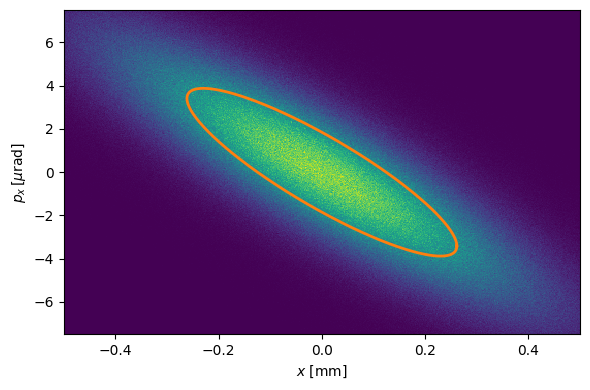

In [46]:
alpha = tw.rows['tcp.c6l7.b1'].alfx[0]
beta = tw.rows['tcp.c6l7.b1'].betx[0]
gamma = tw.rows['tcp.c6l7.b1'].gamx[0]
eps = 3.5e-6 / tw.gamma0

n_part = 10_000_000
cov = eps * np.array([
    [beta,  -alpha],
    [-alpha, gamma],
])

# Optional sanity check: beta*gamma - alpha^2 should be 1
print("beta*gamma - alpha^2 =", beta * gamma - alpha**2)

# Sample Gaussian beam
mean = np.array([0.0, 0.0])
xx, pxx = np.random.multivariate_normal(mean, cov, size=n_part).T
mask = (np.abs(xx) < 5e-4) & (np.abs(pxx) < 7.5e-6)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
# ax.scatter(1e3*xx, 1e6*pxx, s=0.2, c='tab:orange')
# ax.plot((1e3*mon.x[0][idx]).tolist() + [1e3*mon.x[0][idx[0]]],
#         (1e6*mon.px[0][idx]).tolist() + [1e6*mon.px[0][idx[0]]], 'tab:blue', lw=2)
h = ax.hist2d(1e3*xx[mask], 1e6*pxx[mask], bins=500, cmap='viridis')
theta = np.linspace(0, 2*np.pi, 1000)
x_ellipse  = np.sqrt(eps * beta) * np.cos(theta)
px_ellipse = (
    -alpha / beta * x_ellipse
    + np.sqrt(eps / beta) * np.sin(theta)
)
ax.plot(1e3*x_ellipse, 1e6*px_ellipse, 'tab:orange', lw=2, label=r'$1\sigma$ ellipse')
ax.set_xlabel('$x$ [mm]')
ax.set_ylabel(r'$p_x\,[\mu\text{rad}]$')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/emittance.png', dpi=300)#, transparent=True)

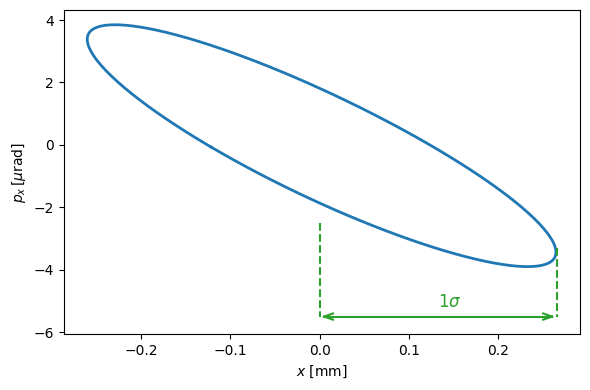

In [81]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot((1e3*mon.x[0][idx]).tolist() + [1e3*mon.x[0][idx[0]]],
        (1e6*mon.px[0][idx]).tolist() + [1e6*mon.px[0][idx[0]]], 'tab:blue', lw=2)
ax.plot([[0.,0.265],[0,0.265]], [[-2.5,-3.3],[-5.5,-5.5]], '--', c='tab:green')
ax.plot([[0.005,0.005,0.005,0.26,0.26],[0.26,0.015,0.015,0.25,0.25]], [[-5.5,-5.5,-5.5,-5.5,-5.5],[-5.5,-5.4,-5.6,-5.4,-5.6]], '-', c='tab:green')
ax.set_xlabel('$x$ [mm]')
ax.set_ylabel(r'$p_x\,[\mu\text{rad}]$')
ax.text(0.1325, -5.2, r'$1\sigma$', fontsize=12, c='tab:green')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/phase_space.png', dpi=300)

In [2]:
k1 = np.array([line[nn].knl[1] / line[nn].length for nn, et in zip(tt.name,tt.element_type) if et == 'Multipole' and len(line[nn].knl) > 1])
k2 = np.array([line[nn].knl[2] / line[nn].length for nn, et in zip(tt.name,tt.element_type) if et == 'Multipole' and len(line[nn].knl) > 2])

In [ ]:
print(7.25e-6 / (12*12/2*max(k1.min(), k1.max())*0.001))
print(7.25e-6 / (12*12/2*max(k2.min(), k2.max())*0.001))

0.011378939209592983
0.00045337631997666806


In [8]:
k2.max()*Brho*0.001

np.float64(5.034244857616001)

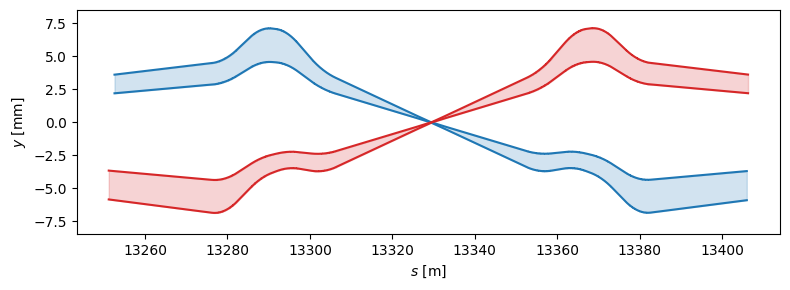

In [ ]:
this_tw    = tw.rows[13251:13407.6:'s']
this_tw_b2 = tw_b2.rows[tw_b2['s'][-1] - 13407.6:tw_b2['s'][-1] - 13251:'s']

fig, ax = plt.subplots(1, 1, figsize=(8, 3))
# twplt = this_tw.plot('', ax=ax)
sigma = np.sqrt(2.5e-6 / this_tw.gamma0 * this_tw.bety)
lll, = ax.plot(this_tw.s, 1e3*this_tw.y + 1e3*sigma, 'tab:blue')
ax.plot(this_tw.s, 1e3*this_tw.y - 1e3*sigma, color=lll.get_color())
ax.fill_between(this_tw.s, 1e3*this_tw.y - 1e3*sigma, 1e3*this_tw.y + 1e3*sigma, color=lll.get_color(), alpha=0.2)
sigma = np.sqrt(2.5e-6 / this_tw_b2.gamma0 * this_tw_b2.bety)
lll, = ax.plot(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y + 1e3*sigma, 'tab:red')
ax.plot(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y - 1e3*sigma, color=lll.get_color())
ax.fill_between(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y - 1e3*sigma, 1e3*this_tw_b2.y + 1e3*sigma, color=lll.get_color(), alpha=0.2)
ax.set_ylim(-8.5, 8.5)
ax.set_xlabel(r'$s$ [m]')
ax.set_ylabel(r'$y$ [mm]')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/beam_crossing.png', dpi=300)

In [24]:
np.sqrt(2.5e-6/tw.gamma0*tw.rows['ip5'].betx[0])

np.float64(7.263282166564279e-06)

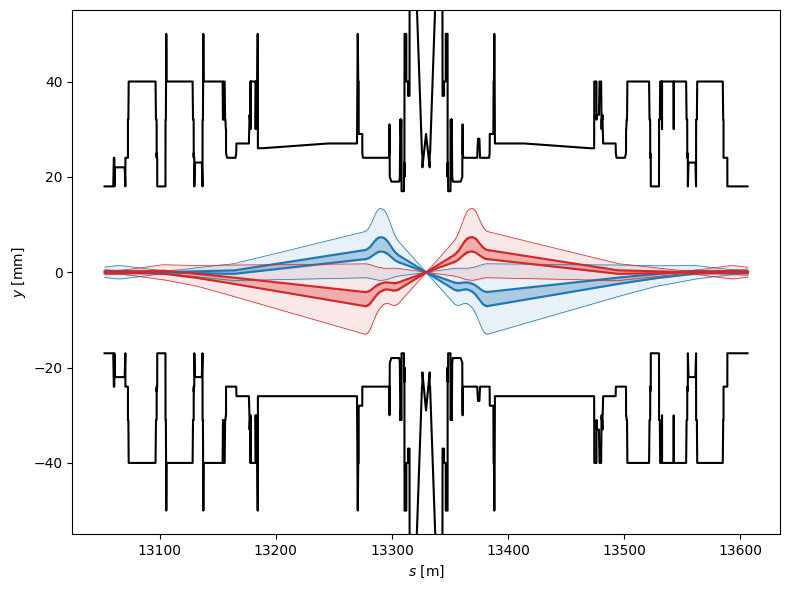

In [55]:
s_start = 13051
s_end   = 13607.6
this_tw    = tw.rows[s_start:s_end:'s']
this_tw_b2 = tw_b2.rows[tw_b2['s'][-1] - s_end:tw_b2['s'][-1] - s_start:'s']

aper = line.get_aperture_table()
aper.x_aper_low += 0.0005
aper.x_aper_high += 0.0005
aper.y_aper_low += 0.0005
aper.y_aper_high += 0.0005
mask = (aper.s >= s_start) & (aper.s <= s_end)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.plot(aper.s[mask], 1e3*aper.y_aper_low[mask], 'k-')
ax.plot(aper.s[mask], 1e3*aper.y_aper_high[mask], 'k-')

sigma = np.sqrt(3.5e-6 / this_tw.gamma0 * this_tw.bety)
ax.plot(this_tw.s, 1e3*this_tw.y + 1e3*sigma, 'tab:blue')
ax.plot(this_tw.s, 1e3*this_tw.y - 1e3*sigma, 'tab:blue')
ax.fill_between(this_tw.s, 1e3*this_tw.y - 1e3*sigma, 1e3*this_tw.y + 1e3*sigma, color='tab:blue', alpha=0.3)
ax.plot(this_tw.s, 1e3*this_tw.y + 1e3*5*sigma, 'tab:blue', lw=0.5)
ax.plot(this_tw.s, 1e3*this_tw.y - 1e3*5*sigma, 'tab:blue', lw=0.5)
ax.fill_between(this_tw.s, 1e3*this_tw.y - 1e3*5*sigma, 1e3*this_tw.y + 1e3*5*sigma, color='tab:blue', alpha=0.1)
sigma = np.sqrt(3.5e-6 / this_tw_b2.gamma0 * this_tw_b2.bety)
ax.plot(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y + 1e3*sigma, 'tab:red')
ax.plot(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y - 1e3*sigma, 'tab:red')
ax.fill_between(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y - 1e3*sigma, 1e3*this_tw_b2.y + 1e3*sigma, color='tab:red', alpha=0.3)
ax.plot(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y + 1e3*5*sigma, 'tab:red', lw=0.5)
ax.plot(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y - 1e3*5*sigma, 'tab:red', lw=0.5)
ax.fill_between(tw_b2['s'][-1] - this_tw_b2.s, 1e3*this_tw_b2.y - 1e3*5*sigma, 1e3*this_tw_b2.y + 1e3*5*sigma, color='tab:red', alpha=0.1)
ax.set_ylim(-55, 55)
ax.set_xlabel(r'$s$ [m]')
ax.set_ylabel(r'$y$ [mm]')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/beam_crossing_aper.png', dpi=300)

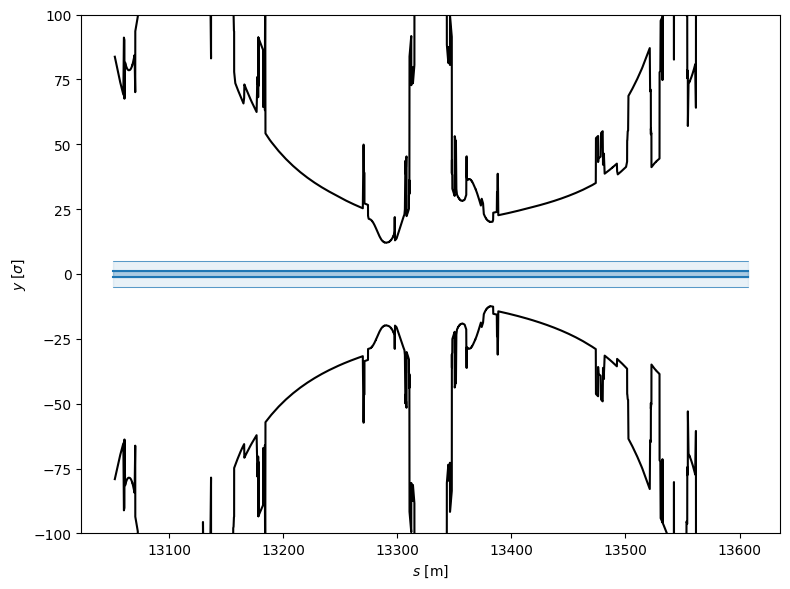

In [60]:
s_start = 13051
s_end   = 13607.6
this_tw    = tw.rows[s_start:s_end:'s']

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sigma = np.sqrt(3.5e-6 / this_tw.gamma0 * this_tw.bety)
ax.plot(aper.s[mask], (aper.y_aper_low[mask] - this_tw.y)/sigma, 'k-')
ax.plot(aper.s[mask], (aper.y_aper_high[mask] - this_tw.y)/sigma, 'k-')

ax.plot([s_start, s_end], [1, 1], 'tab:blue')
ax.plot([s_start, s_end], [-1, -1], 'tab:blue')
ax.fill_between([s_start, s_end], [-1, -1], [1, 1], color='tab:blue', alpha=0.3)
ax.plot([s_start, s_end], [5, 5], 'tab:blue', lw=0.5)
ax.plot([s_start, s_end], [-5, -5], 'tab:blue', lw=0.5)
ax.fill_between([s_start, s_end], [-5, -5], [5, 5], color='tab:blue', alpha=0.1)
ax.set_ylim(-100, 100)
ax.set_xlabel(r'$s$ [m]')
ax.set_ylabel(r'$y\;[\sigma]$')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/beam_crossing_aper_inv.png', dpi=300)

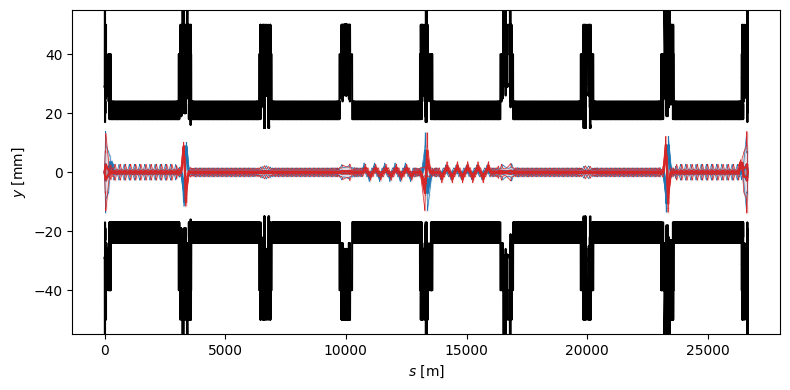

In [53]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.plot(aper.s, 1e3*aper.y_aper_low, 'k-')
ax.plot(aper.s, 1e3*aper.y_aper_high, 'k-')

sigma = np.sqrt(3.5e-6 / tw.gamma0 * tw.bety)
ax.plot(tw.s, 1e3*tw.y + 1e3*sigma, 'tab:blue')
ax.plot(tw.s, 1e3*tw.y - 1e3*sigma, 'tab:blue')
ax.fill_between(tw.s, 1e3*tw.y - 1e3*sigma, 1e3*tw.y + 1e3*sigma, color='tab:blue', alpha=0.3)
ax.plot(tw.s, 1e3*tw.y + 1e3*5*sigma, 'tab:blue', lw=0.5)
ax.plot(tw.s, 1e3*tw.y - 1e3*5*sigma, 'tab:blue', lw=0.5)
ax.fill_between(tw.s, 1e3*tw.y - 1e3*5*sigma, 1e3*tw.y + 1e3*5*sigma, color='tab:blue', alpha=0.1)
sigma = np.sqrt(3.5e-6 / tw_b2.gamma0 * tw_b2.bety)
ax.plot(tw_b2['s'][-1] - tw_b2.s, 1e3*tw_b2.y + 1e3*sigma, 'tab:red')
ax.plot(tw_b2['s'][-1] - tw_b2.s, 1e3*tw_b2.y - 1e3*sigma, 'tab:red')
ax.fill_between(tw_b2['s'][-1] - tw_b2.s, 1e3*tw_b2.y - 1e3*sigma, 1e3*tw_b2.y + 1e3*sigma, color='tab:red', alpha=0.3)
ax.plot(tw_b2['s'][-1] - tw_b2.s, 1e3*tw_b2.y + 1e3*5*sigma, 'tab:red', lw=0.5)
ax.plot(tw_b2['s'][-1] - tw_b2.s, 1e3*tw_b2.y - 1e3*5*sigma, 'tab:red', lw=0.5)
ax.fill_between(tw_b2['s'][-1] - tw_b2.s, 1e3*tw_b2.y - 1e3*5*sigma, 1e3*tw_b2.y + 1e3*5*sigma, color='tab:red', alpha=0.1)
ax.set_ylim(-55, 55)
ax.set_xlabel(r'$s$ [m]')
ax.set_ylabel(r'$y$ [mm]')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/full_aper.png', dpi=300)

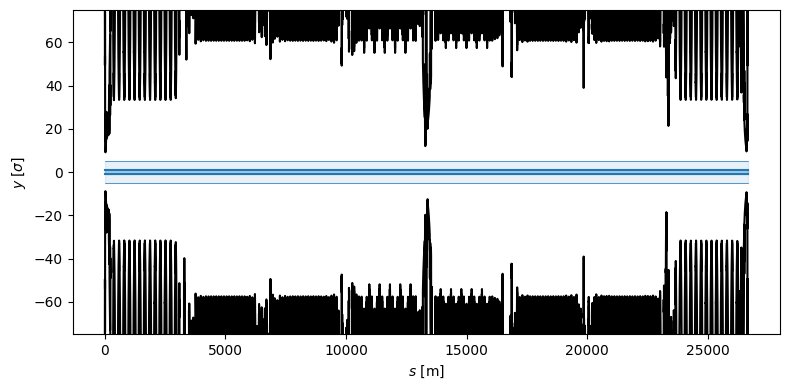

In [54]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
sigma = np.sqrt(3.5e-6 / tw.gamma0 * tw.bety)
ax.plot(aper.s, (aper.y_aper_low - tw.y)/sigma, 'k-')
ax.plot(aper.s, (aper.y_aper_high - tw.y)/sigma, 'k-')

ax.plot([0, tw.s[-1]], [1, 1], 'tab:blue')
ax.plot([0, tw.s[-1]], [-1, -1], 'tab:blue')
ax.fill_between([0, tw.s[-1]], [-1, -1], [1, 1], color='tab:blue', alpha=0.3)
ax.plot([0, tw.s[-1]], [5, 5], 'tab:blue', lw=0.5)
ax.plot([0, tw.s[-1]], [-5, -5], 'tab:blue', lw=0.5)
ax.fill_between([0, tw.s[-1]], [-5, -5], [5, 5], color='tab:blue', alpha=0.1)
ax.set_ylim(-75, 75)
ax.set_xlabel(r'$s$ [m]')
ax.set_ylabel(r'$y\;[\sigma]$')
plt.tight_layout()
plt.savefig('/Users/frederik/Downloads/full_aper_inv.png', dpi=300)

In [62]:
x_old = tw.x.copy()
y_old = tw.y.copy()
betx_old = tw.betx.copy()
bety_old = tw.bety.copy()

In [ ]:
line['mqxa.1r1..1/lhcb1'].shift_x
tw_after_shift = line.twiss()

np.float64(0.005)

Text(0, 0.5, '$y$ [mm]')

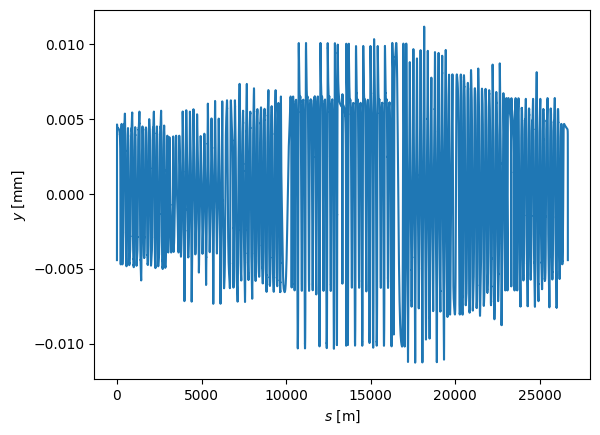

In [81]:
plt.plot(tw.s, (tw.betx - tw_after_shift.betx)/tw.betx)
plt.xlabel(r'$s$ [m]')
plt.ylabel(r'$y$ [mm]')